In [18]:
import pandas as pd

# Membaca dataset
df = pd.read_csv("insurance.csv")

# Menampilkan 5 baris pertama
print("LIMA DATA PERTAMA:")
print(df.head())

# Menampilkan ukuran dataset
print("\nUKURAN DATASET:")
print(df.shape)

# Menampilkan nama kolom
print("\nNAMA KOLOM:")
print(df.columns.tolist())

LIMA DATA PERTAMA:
   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520

UKURAN DATASET:
(1338, 7)

NAMA KOLOM:
['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']


In [19]:
print("\nINFORMASI DATA:")
df.info()

print("\nJUMLAH DATA KOSONG:")
print(df.isnull().sum())

print("\nJUMLAH DATA DUPLIKAT:")
print(df.duplicated().sum())


INFORMASI DATA:
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB

JUMLAH DATA KOSONG:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

JUMLAH DATA DUPLIKAT:
1


In [20]:
# Menghapus baris yang benar-benar duplikat
df = df.drop_duplicates()

print("\nUKURAN DATA SETELAH CLEANING:")
print(df.shape)


UKURAN DATA SETELAH CLEANING:
(1337, 7)


In [21]:
print("\nDATA KOSONG SETELAH CLEANING:")
print(df.isnull().sum())

print("\nDATA DUPLIKAT SETELAH CLEANING:")
print(df.duplicated().sum())


DATA KOSONG SETELAH CLEANING:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

DATA DUPLIKAT SETELAH CLEANING:
0


In [22]:
# ==========================================
# TAHAP 4: EDA
# ==========================================

print("\nSTATISTIK DESKRIPTIF:")
print(df.describe())

print("\nJUMLAH SETIAP KATEGORI:")
print(df["smoker"].value_counts())

print("\nJUMLAH DATA PER WILAYAH:")
print(df["region"].value_counts())


STATISTIK DESKRIPTIF:
               age          bmi     children       charges
count  1337.000000  1337.000000  1337.000000   1337.000000
mean     39.222139    30.663452     1.095737  13279.121487
std      14.044333     6.100468     1.205571  12110.359656
min      18.000000    15.960000     0.000000   1121.873900
25%      27.000000    26.290000     0.000000   4746.344000
50%      39.000000    30.400000     1.000000   9386.161300
75%      51.000000    34.700000     2.000000  16657.717450
max      64.000000    53.130000     5.000000  63770.428010

JUMLAH SETIAP KATEGORI:
smoker
no     1063
yes     274
Name: count, dtype: int64

JUMLAH DATA PER WILAYAH:
region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64


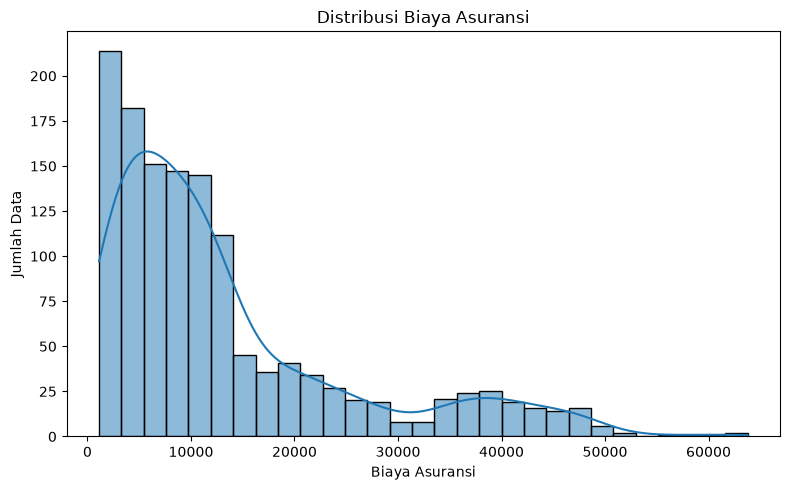

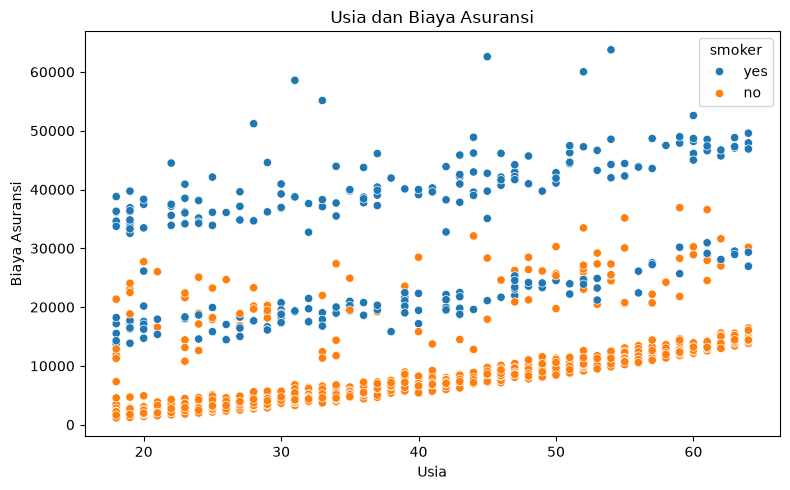

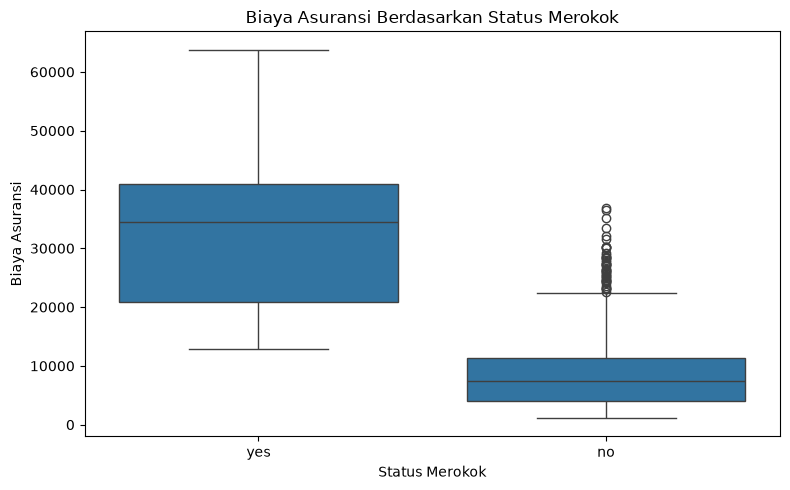

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

# Distribusi biaya asuransi
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="charges", kde=True)
plt.title("Distribusi Biaya Asuransi")
plt.xlabel("Biaya Asuransi")
plt.ylabel("Jumlah Data")
plt.tight_layout()
plt.show()

# Hubungan usia dengan biaya asuransi
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="age", y="charges", hue="smoker")
plt.title("Usia dan Biaya Asuransi")
plt.xlabel("Usia")
plt.ylabel("Biaya Asuransi")
plt.tight_layout()
plt.show()

# Perbandingan biaya asuransi berdasarkan status merokok
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="smoker", y="charges")
plt.title("Biaya Asuransi Berdasarkan Status Merokok")
plt.xlabel("Status Merokok")
plt.ylabel("Biaya Asuransi")
plt.tight_layout()
plt.show()

In [24]:
print("\nRATA-RATA BIAYA BERDASARKAN STATUS MEROKOK:")
print(df.groupby("smoker")["charges"].mean().round(2))

print("\nRATA-RATA BIAYA BERDASARKAN WILAYAH:")
print(df.groupby("region")["charges"].mean().round(2))

print("\nRATA-RATA BIAYA BERDASARKAN STATUS MEROKOK DAN WILAYAH:")
print(
    df.groupby(["smoker", "region"])["charges"]
    .mean()
    .round(2)
)


RATA-RATA BIAYA BERDASARKAN STATUS MEROKOK:
smoker
no      8440.66
yes    32050.23
Name: charges, dtype: float64

RATA-RATA BIAYA BERDASARKAN WILAYAH:
region
northeast    13406.38
northwest    12450.84
southeast    14735.41
southwest    12346.94
Name: charges, dtype: float64

RATA-RATA BIAYA BERDASARKAN STATUS MEROKOK DAN WILAYAH:
smoker  region   
no      northeast     9165.53
        northwest     8582.47
        southeast     8032.22
        southwest     8019.28
yes     northeast    29673.54
        northwest    30192.00
        southeast    34845.00
        southwest    32269.06
Name: charges, dtype: float64


In [25]:
# Menentukan fitur dan target
X = df.drop(columns=["charges"])
y = df["charges"]

print("Fitur:")
print(X.head())

print("\nTarget:")
print(y.head())

Fitur:
   age     sex     bmi  children smoker     region
0   19  female  27.900         0    yes  southwest
1   18    male  33.770         1     no  southeast
2   28    male  33.000         3     no  southeast
3   33    male  22.705         0     no  northwest
4   32    male  28.880         0     no  northwest

Target:
0    16884.92400
1     1725.55230
2     4449.46200
3    21984.47061
4     3866.85520
Name: charges, dtype: float64


In [26]:
from sklearn.model_selection import train_test_split

# Membagi data menjadi training dan testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

Jumlah data training: 1069
Jumlah data testing: 268


In [27]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Memisahkan kolom numerik dan kategorikal
kolom_numerik = ["age", "bmi", "children"]
kolom_kategori = ["sex", "smoker", "region"]

# Menentukan cara pengolahan tiap jenis data
preprocessor = ColumnTransformer(
    transformers=[
        ("numerik", StandardScaler(), kolom_numerik),
        (
            "kategori",
            OneHotEncoder(handle_unknown="ignore"),
            kolom_kategori
        )
    ]
)

# Model pertama: Linear Regression
model_linear = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LinearRegression())
])

# Model kedua: Random Forest
model_rf = Pipeline([
    ("preprocessing", preprocessor),
    (
        "model",
        RandomForestRegressor(
            n_estimators=200,
            random_state=42
        )
    )
])

In [28]:
# Melatih model Linear Regression
model_linear.fit(X_train, y_train)

# Melatih model Random Forest
model_rf.fit(X_train, y_train)

print("Kedua model berhasil dilatih.")

Kedua model berhasil dilatih.


In [29]:
# Prediksi biaya asuransi pada data testing
prediksi_linear = model_linear.predict(X_test)
prediksi_rf = model_rf.predict(X_test)

print("Lima prediksi Linear Regression:")
print(prediksi_linear[:5])

print("\nLima prediksi Random Forest:")
print(prediksi_rf[:5])

print("\nLima biaya aktual:")
print(y_test.iloc[:5].to_numpy())

Lima prediksi Linear Regression:
[ 8143.69388412  5737.11568259 14369.31487618 31745.51363586
  8962.38665706]

Lima prediksi Random Forest:
[10293.58380005  6830.88052285 11930.3497916  42671.46393245
  6291.93901905]

Lima biaya aktual:
[ 8688.85885  5708.867   11436.73815 38746.3551   4463.2051 ]


In [30]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

def evaluasi_model(nama, aktual, prediksi):
    mae = mean_absolute_error(aktual, prediksi)
    rmse = np.sqrt(mean_squared_error(aktual, prediksi))
    r2 = r2_score(aktual, prediksi)

    print(f"\nHasil {nama}")
    print(f"MAE  : {mae:.2f}")
    print(f"RMSE : {rmse:.2f}")
    print(f"R2   : {r2:.4f}")

evaluasi_model(
    "Linear Regression",
    y_test,
    prediksi_linear
)

evaluasi_model(
    "Random Forest",
    y_test,
    prediksi_rf
)


Hasil Linear Regression
MAE  : 4177.05
RMSE : 5956.34
R2   : 0.8069

Hasil Random Forest
MAE  : 2563.89
RMSE : 4642.21
R2   : 0.8827


In [34]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Memisahkan fitur dan target
X = df.drop("charges", axis=1)
y = df["charges"]

# Membagi dataset 80:20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Menentukan kolom numerik dan kategorikal
numeric_features = ["age", "bmi", "children"]
categorical_features = ["sex", "smoker", "region"]

# Membuat preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Melatih preprocessing dengan data training
X_train_processed = preprocessor.fit_transform(X_train)

# Mengubah data testing menggunakan preprocessing yang sama
X_test_processed = preprocessor.transform(X_test)

print("Preprocessing berhasil!")
print("Data training:", X_train_processed.shape)
print("Data testing:", X_test_processed.shape)

Preprocessing berhasil!
Data training: (1069, 11)
Data testing: (268, 11)


In [35]:
from sklearn.linear_model import LinearRegression

model_lr = LinearRegression()

model_lr.fit(X_train_processed, y_train)

pred_lr = model_lr.predict(X_test_processed)

print("Prediksi biaya asuransi:")
print(pred_lr[:5])

Prediksi biaya asuransi:
[ 8143.69388412  5737.11568259 14369.31487618 31745.51363586
  8962.38665706]


In [36]:
from sklearn.ensemble import RandomForestRegressor

model_rf = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

model_rf.fit(X_train_processed, y_train)
pred_rf = model_rf.predict(X_test_processed)